<a href="https://colab.research.google.com/github/ilyassboudrioua/qr-shield-mlops/blob/main/notebooks/02_qr_codes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module QR codes
## Étape QR.1 : Téléchargement et exploration du Quishing Dataset

Dataset : Trad & Chehab (2025), 9 987 QR codes de 69 × 69 pixels, licence CC BY 4.0.
Chaque QR code est déjà sous forme de tableau de nombres (une case = un pixel).
Label : 1 = phishing, 0 = sûr.

Remarque de sécurité : les fichiers sont au format "pickle", qui peut exécuter du code à l'ouverture.
La source est un dépôt de chercheurs, et on l'ouvre dans Colab (machine isolée), jamais sur un PC personnel.

## Préparation
Connexion au Google Drive, installation des bibliothèques et chemins du projet.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

!pip install -q xgboost lightgbm shap opencv-python-headless

import os
DATA = '/content/drive/MyDrive/QR-Shield/data'
MODELS = '/content/drive/MyDrive/QR-Shield/models'
print("data :", os.path.exists(DATA), "| models :", os.path.exists(MODELS))

Mounted at /content/drive
data : True | models : True


Images : (9987, 69, 69) | type : int16
Valeurs des pixels : [0 1]
Labels : {np.int32(0): np.int64(5005), np.int32(1): np.int64(4982)}


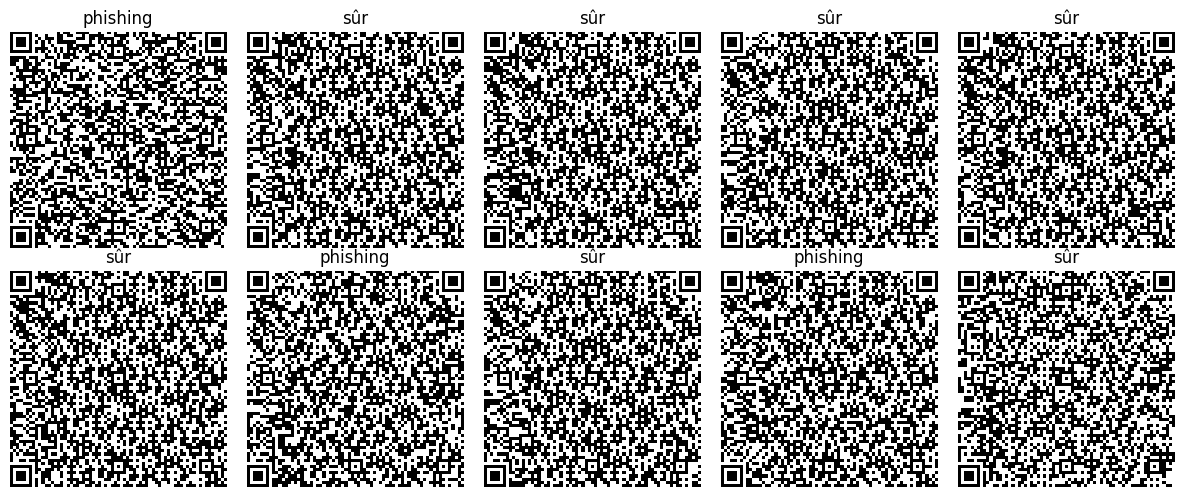

In [3]:
import pickle, numpy as np, matplotlib.pyplot as plt

# 1. Télécharger le dépôt et décompresser le dataset dans le Drive
QR_DIR = f"{DATA}/qr"
os.makedirs(QR_DIR, exist_ok=True)
!git clone -q https://github.com/fouadtrad/Detecting-Quishing-Attacks-with-Machine-Learning-Techniques-Through-QR-Code-Analysis.git /content/quishing
!unzip -oq /content/quishing/QuishingDataset.zip -d {QR_DIR}

# 2. Charger les images et les labels
with open(f"{QR_DIR}/qr_codes_29.pickle", "rb") as f:
    qr_images = pickle.load(f)
with open(f"{QR_DIR}/qr_codes_29_labels.pickle", "rb") as f:
    qr_labels = np.array(pickle.load(f))

# 3. Explorer
print("Images :", qr_images.shape, "| type :", qr_images.dtype)
print("Valeurs des pixels :", np.unique(qr_images)[:10])
print("Labels :", dict(zip(*np.unique(qr_labels, return_counts=True))))

# 4. Afficher 10 QR codes au hasard
np.random.seed(42)
idx = np.random.choice(len(qr_images), 10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, i in zip(axes.flat, idx):
    ax.imshow(qr_images[i], cmap="gray")
    ax.set_title("phishing" if qr_labels[i] == 1 else "sûr")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Étape QR.2 : Décodage des QR codes

On lit le lien caché dans chaque QR code avec OpenCV, comme le ferait l'appareil photo d'un téléphone.
Le lien est seulement lu comme du texte : il n'est jamais ouvert.

Deux préparations sont nécessaires avant la lecture :
- agrandir l'image (69 pixels, c'est trop petit pour le lecteur) ;
- ajouter une marge blanche autour, la "zone de silence" qu'exige la norme QR code.

In [4]:
import cv2
import pandas as pd

lecteur = cv2.QRCodeDetector()

def decoder(qr, inverser=False):
    img = (qr * 255).astype(np.uint8)           # 0 / 1  ->  0 / 255
    if inverser:
        img = 255 - img                          # au cas où noir et blanc sont inversés
    img = cv2.resize(img, (69 * 8, 69 * 8), interpolation=cv2.INTER_NEAREST)  # agrandir
    img = cv2.copyMakeBorder(img, 40, 40, 40, 40, cv2.BORDER_CONSTANT, value=255)  # marge blanche
    texte, _, _ = lecteur.detectAndDecode(img)
    return texte

# Tester les deux sens de couleurs sur 50 QR codes pour choisir le bon
ok_normal = sum(bool(decoder(q)) for q in qr_images[:50])
ok_inverse = sum(bool(decoder(q, inverser=True)) for q in qr_images[:50])
INVERSER = ok_inverse > ok_normal
print(f"Décodés sur 50 : normal = {ok_normal}, inversé = {ok_inverse} -> inverser = {INVERSER}")

# Décoder les 9 987 QR codes
liens = [decoder(q, INVERSER) for q in qr_images]
qr_df = pd.DataFrame({"url": liens, "label": qr_labels})

print("\nQR codes décodés :", (qr_df["url"] != "").sum(), "sur", len(qr_df))
print("Échecs par classe :", qr_df[qr_df["url"] == ""]["label"].value_counts().to_dict())
print("\nExemples :")
print(qr_df[qr_df["url"] != ""].groupby("label").head(3).to_string())

qr_df.to_csv(f"{DATA}/qr/qr_liens.csv", index=False)

Décodés sur 50 : normal = 43, inversé = 0 -> inverser = False

QR codes décodés : 8882 sur 9987
Échecs par classe : {1: 570, 0: 535}

Exemples :
                                                                                                url  label
0                                                                    www.ecslimited.com/environ.cfm      0
1                                       complexesadiya.com/www/paypal/co/uk/cgi-bin/login_error.php      1
2               docs.google.com/forms/d/1jYSjccJBBY5nfU1vgFfWSm-fAq3pY82jBl6NMFl_GQA/viewform?pli=1      1
3   www309.paypal.ca.98990.securessl-150.mx/js/web.apps/ca/m.pp/?cmnd=_lg&nav=_74F5AC04FE72C1BBC18C      1
7                                                                      webcentre.co.nz/compress.htm      0
11                                                     tech.groups.yahoo.com/group/peoplesoft-fans/      0


## Étape QR.3 : Réutiliser le modèle des liens

1. On découpe les QR codes en entraînement (80 %) et test (20 %). Ce découpage servira pour tous les modèles QR.
2. On applique le modèle des liens (déjà entraîné sur PhreshPhish) aux liens décodés du test, sans le réentraîner.
3. Les liens décodés n'ont pas de "http://" : on teste les deux versions, "http://" et "https://", pour mesurer l'effet de ce détail.

C'est un test de transfert : le modèle marche-t-il sur des données différentes de celles qu'il a apprises ?

In [5]:
import re, math, joblib, json
from urllib.parse import urlparse
from collections import Counter
from sklearn.model_selection import train_test_split
from scipy.sparse import hstack, csr_matrix
from sklearn.metrics import (confusion_matrix, recall_score, precision_score, f1_score,
                             matthews_corrcoef, roc_auc_score)

# 1. Découpage 80/20, stratifié, identique pour tous les modèles QR
idx_tr, idx_te = train_test_split(np.arange(len(qr_df)), test_size=0.2,
                                  stratify=qr_df["label"], random_state=42)

# 2. Recharger le modèle des liens (v2) et ses outils
tfidf_l = joblib.load(f"{MODELS}/links_tfidf_v2.joblib")
xgb_l = joblib.load(f"{MODELS}/links_xgb_v2.joblib")
infos_l = json.load(open(f"{MODELS}/links_infos_v2.json"))
SEUIL_L = infos_l["seuil"]

MOTS_SUSPECTS = ["login", "verify", "account", "update", "secure", "bank",
                 "signin", "confirm", "password", "wallet", "support", "billing"]
def entropie(t):
    if not t: return 0.0
    f = Counter(t); return -sum((n/len(t))*math.log2(n/len(t)) for n in f.values())
def features_url(url):
    p = urlparse(url); host = p.hostname or ""
    return {"longueur_url": len(url), "longueur_host": len(host), "longueur_chemin": len(p.path),
            "nb_points": url.count("."), "nb_tirets": url.count("-"),
            "nb_chiffres": sum(c.isdigit() for c in url), "nb_sous_domaines": max(host.count(".") - 1, 0),
            "a_arobase": int("@" in url), "host_est_ip": int(bool(re.fullmatch(r"\d{1,3}(\.\d{1,3}){3}", host))),
            "https": int(p.scheme == "https"), "entropie": round(entropie(url), 3),
            "nb_mots_suspects": sum(m in url.lower() for m in MOTS_SUSPECTS)}

def score_liens(urls):
    urls = [u.split("?")[0].split("#")[0] for u in urls]          # même traitement que le modèle v2
    X = pd.DataFrame([features_url(u) for u in urls])[infos_l["features"]]
    Xc = hstack([csr_matrix(X.values), tfidf_l.transform(urls)]).tocsr()
    return xgb_l.predict_proba(Xc)[:, 1]

def evaluer(nom, y, proba, seuil=0.5):
    pred = (proba >= seuil).astype(int); tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {"Modèle": nom, "TP": tp, "FN": fn, "FP": fp, "TN": tn, "Recall": recall_score(y, pred),
            "Precision": precision_score(y, pred), "FPR": fp/(fp+tn),
            "MCC": matthews_corrcoef(y, pred), "ROC-AUC": roc_auc_score(y, proba)}

# 3. Appliquer le modèle aux liens décodés du test (http:// puis https://)
test_lu = qr_df.iloc[idx_te]
test_lu = test_lu[test_lu["url"] != ""]
print("QR codes du test :", len(idx_te), "| dont liens lus :", len(test_lu))

resultats_qr = pd.DataFrame([
    evaluer("Modèle liens, préfixe http://", test_lu["label"], score_liens("http://" + test_lu["url"]), SEUIL_L),
    evaluer("Modèle liens, préfixe https://", test_lu["label"], score_liens("https://" + test_lu["url"]), SEUIL_L),
]).set_index("Modèle")
resultats_qr.round(3)

QR codes du test : 1998 | dont liens lus : 1799


,TP,FN,FP,TN,Recall,Precision,FPR,MCC,ROC-AUC
Modèle,,,,,,,,,
"Modèle liens, préfixe http://",853,41,517,388,0.954,0.623,0.571,0.449,0.893
"Modèle liens, préfixe https://",607,287,69,836,0.679,0.898,0.076,0.622,0.892


## Étape QR.4 : Modèle entraîné sur les liens décodés des QR codes

Le modèle des liens dépend trop du préfixe "https", absent des QR codes (dérive des données).
On entraîne donc un modèle dédié, sur les liens décodés des QR codes d'entraînement :
- mêmes features qu'avant, sans "https" (toujours absent ici) ;
- TF-IDF appris sur ces liens ;
- XGBoost.

On garde 20 % de l'entraînement comme validation, pour choisir le seuil à l'étape QR.6.

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from xgboost import XGBClassifier

# 1. Découper l'entraînement en entraînement / validation (pour le seuil plus tard)
idx_tr2, idx_val = train_test_split(idx_tr, test_size=0.2, stratify=qr_df["label"].iloc[idx_tr], random_state=42)

def partie_lue(idx):
    d = qr_df.iloc[idx]
    return d[d["url"] != ""]

tr, va, te = partie_lue(idx_tr2), partie_lue(idx_val), partie_lue(idx_te)
print("Liens lus  -> entraînement :", len(tr), "| validation :", len(va), "| test :", len(te))

# 2. Features sans "https" + TF-IDF appris sur l'entraînement seulement
def feats(urls):
    return pd.DataFrame([features_url("http://" + u) for u in urls]).drop(columns="https")

tfidf_qr = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), max_features=20000, min_df=3)
Xq_tr = hstack([csr_matrix(feats(tr["url"]).values), tfidf_qr.fit_transform(tr["url"])]).tocsr()
Xq_va = hstack([csr_matrix(feats(va["url"]).values), tfidf_qr.transform(va["url"])]).tocsr()
Xq_te = hstack([csr_matrix(feats(te["url"]).values), tfidf_qr.transform(te["url"])]).tocsr()

# 3. Entraîner XGBoost
xgb_qr_lien = XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.1, subsample=0.8,
                            colsample_bytree=0.8, tree_method="hist", eval_metric="logloss",
                            random_state=42, n_jobs=-1)
xgb_qr_lien.fit(Xq_tr, tr["label"])

# 4. Comparer avec le modèle des liens réutilisé (sur le même test)
resultats_qr = pd.concat([resultats_qr, pd.DataFrame([
    evaluer("Modèle dédié aux liens décodés (seuil 0,5)", te["label"], xgb_qr_lien.predict_proba(Xq_te)[:, 1])
]).set_index("Modèle")])
resultats_qr.round(3)

Liens lus  -> entraînement : 5673 | validation : 1410 | test : 1799


,TP,FN,FP,TN,Recall,Precision,FPR,MCC,ROC-AUC
Modèle,,,,,,,,,
"Modèle liens, préfixe http://",853,41,517,388,0.954,0.623,0.571,0.449,0.893
"Modèle liens, préfixe https://",607,287,69,836,0.679,0.898,0.076,0.622,0.892
"Modèle dédié aux liens décodés (seuil 0,5)",851,43,34,871,0.952,0.962,0.038,0.914,0.990


## Étape QR.5 : Modèle sur les pixels de l'image

Le modèle des liens ne marche que si le QR code a pu être lu (89 % des cas).
On entraîne donc aussi un modèle qui regarde directement l'image : les 69 × 69 = 4 761 pixels deviennent 4 761 features (0 ou 1).
C'est l'approche des chercheurs qui ont publié le dataset (ils obtiennent une ROC-AUC de 0,91 avec XGBoost).
Avantage : on n'a même pas besoin de lire le lien.
On compare une baseline (régression logistique) et XGBoost, sur tous les QR codes du test (y compris ceux non lus).

In [7]:
from sklearn.linear_model import LogisticRegression

# Chaque image 69x69 devient une ligne de 4 761 pixels
P_tr = qr_images[idx_tr2].reshape(len(idx_tr2), -1)
P_te = qr_images[idx_te].reshape(len(idx_te), -1)
y_tr_p, y_te_p = qr_labels[idx_tr2], qr_labels[idx_te]
print("Entraînement :", P_tr.shape, "| Test :", P_te.shape)

# Baseline : régression logistique
base_pix = LogisticRegression(max_iter=2000, C=0.1)
base_pix.fit(P_tr, y_tr_p)

# Modèle principal : XGBoost
xgb_pix = XGBClassifier(n_estimators=500, max_depth=6, learning_rate=0.05, subsample=0.8,
                        colsample_bytree=0.5, tree_method="hist", eval_metric="logloss",
                        random_state=42, n_jobs=-1)
xgb_pix.fit(P_tr, y_tr_p)

resultats_pix = pd.DataFrame([
    evaluer("Pixels : baseline (LogReg)", y_te_p, base_pix.predict_proba(P_te)[:, 1]),
    evaluer("Pixels : XGBoost", y_te_p, xgb_pix.predict_proba(P_te)[:, 1]),
]).set_index("Modèle")
resultats_pix.round(3)

Entraînement : (6391, 4761) | Test : (1998, 4761)


,TP,FN,FP,TN,Recall,Precision,FPR,MCC,ROC-AUC
Modèle,,,,,,,,,
Pixels : baseline (LogReg),770,227,174,827,0.772,0.816,0.174,0.599,0.874
Pixels : XGBoost,812,185,138,863,0.814,0.855,0.138,0.677,0.914


## Étape QR.6 : Fusion du modèle "lien" et du modèle "image"

Règle de décision :
- si le lien a pu être lu : score = w × score du lien + (1 − w) × score de l'image ;
- si le lien n'a pas pu être lu : score = score de l'image seule.

On choisit le poids w et le seuil sur la VALIDATION (budget : 5 % de fausses alertes au maximum),
puis on mesure une seule fois sur le TEST. On compare trois options : image seule, lien seul, fusion.
C'est le test de l'hypothèse H2.

In [8]:
from sklearn.metrics import roc_curve

def scores(idx):
    d = qr_df.iloc[idx].reset_index(drop=True)
    p_pix = xgb_pix.predict_proba(qr_images[idx].reshape(len(idx), -1))[:, 1]
    p_lien = np.full(len(idx), np.nan)
    lu = (d["url"] != "").values
    u = d.loc[lu, "url"]
    X = hstack([csr_matrix(feats(u).values), tfidf_qr.transform(u)]).tocsr()
    p_lien[lu] = xgb_qr_lien.predict_proba(X)[:, 1]
    return d["label"].values, p_pix, p_lien

def combiner(p_pix, p_lien, w):
    return np.where(np.isnan(p_lien), p_pix, w * p_lien + (1 - w) * p_pix)

def seuil_budget(y, p, fpr_max=0.05):
    fpr, tpr, s = roc_curve(y, p); ok = fpr <= fpr_max
    return float(s[ok][tpr[ok].argmax()])

y_va, pix_va, lien_va = scores(idx_val)
y_te, pix_te, lien_te = scores(idx_te)

# 1. Choisir le poids w sur la validation (meilleure ROC-AUC)
for w in [0.5, 0.7, 0.8, 0.9, 1.0]:
    print(f"w = {w} -> ROC-AUC validation : {roc_auc_score(y_va, combiner(pix_va, lien_va, w)):.4f}")
W = max([0.5, 0.7, 0.8, 0.9, 1.0], key=lambda w: roc_auc_score(y_va, combiner(pix_va, lien_va, w)))

# 2. Pour chaque option : seuil choisi sur la validation, mesure unique sur le test
options = {"Image seule": (0.0, pix_va, pix_te),
           "Lien seul (image si non lu)": (1.0, None, None),
           f"Fusion (w = {W})": (W, None, None)}
lignes = []
for nom, (w, pv, pt) in options.items():
    pv = combiner(pix_va, lien_va, w) if pv is None else pv
    pt = combiner(pix_te, lien_te, w) if pt is None else pt
    s = seuil_budget(y_va, pv)
    lignes.append({**evaluer(nom, y_te, pt, seuil=s), "Seuil": s})
final_qr = pd.DataFrame(lignes).set_index("Modèle")
SEUIL_QR = final_qr.loc[f"Fusion (w = {W})", "Seuil"]
print(f"\nPoids retenu : w = {W} | seuil retenu : {SEUIL_QR:.3f}")
final_qr.round(3)

w = 0.5 -> ROC-AUC validation : 0.9759
w = 0.7 -> ROC-AUC validation : 0.9818
w = 0.8 -> ROC-AUC validation : 0.9837
w = 0.9 -> ROC-AUC validation : 0.9852
w = 1.0 -> ROC-AUC validation : 0.9860

Poids retenu : w = 1.0 | seuil retenu : 0.572


,TP,FN,FP,TN,Recall,Precision,FPR,MCC,ROC-AUC,Seuil
Modèle,,,,,,,,,,
Image seule,664,333,40,961,0.666,0.943,0.040,0.655,0.914,0.806
Lien seul (image si non lu),923,74,38,963,0.926,0.960,0.038,0.888,0.986,0.572
Fusion (w = 1.0),923,74,38,963,0.926,0.960,0.038,0.888,0.986,0.572


## Étape QR.7 : Vérification de la fuite par domaine, rôle de l'image, sauvegarde

1. Les résultats sont très bons (ROC-AUC 0,986) et le découpage s'est fait au hasard (pas de dates).
   On vérifie si le modèle reconnaît des sites déjà vus à l'entraînement plutôt que l'attaque.
2. On mesure le modèle image seul sur les QR codes illisibles du test, ceux où il sert de secours.
3. On sauvegarde les modèles, le seuil et les règles de décoding dans le Drive.

In [9]:
# 1. Fuite par domaine : domaines du test déjà présents dans l'entraînement ?
hote = lambda u: urlparse("http://" + u).hostname or ""
hotes_train = set(pd.concat([tr["url"], va["url"]]).map(hote))
deja_vu = te["url"].map(hote).isin(hotes_train).values
p_lien_te = xgb_qr_lien.predict_proba(Xq_te)[:, 1]
y_lu = te["label"].values
print("Liens du test dont le domaine est déjà dans l'entraînement :", round(deja_vu.mean(), 3))
domaines = pd.DataFrame([
    evaluer("Domaine déjà vu", y_lu[deja_vu], p_lien_te[deja_vu], SEUIL_QR),
    evaluer("Domaine nouveau", y_lu[~deja_vu], p_lien_te[~deja_vu], SEUIL_QR),
]).set_index("Modèle")
print(domaines[["TP", "FN", "FP", "TN", "Recall", "Precision", "FPR"]].round(3), "\n")

# 2. Le modèle image sur les QR codes illisibles du test (son rôle de secours)
non_lu = np.isnan(lien_te)
print("QR codes illisibles dans le test :", non_lu.sum())
print(pd.DataFrame([evaluer("Image seule, QR illisibles", y_te[non_lu], pix_te[non_lu], SEUIL_QR)])
      .set_index("Modèle")[["TP", "FN", "FP", "TN", "Recall", "Precision", "FPR"]].round(3), "\n")

# 3. Sauvegarder
joblib.dump(tfidf_qr, f"{MODELS}/qr_tfidf.joblib")
joblib.dump(xgb_qr_lien, f"{MODELS}/qr_xgb_lien.joblib")
joblib.dump(xgb_pix, f"{MODELS}/qr_xgb_pixels.joblib")
infos_qr = {"regle": "lien décodé si lisible, sinon image", "poids_w": W, "seuil": SEUIL_QR,
            "decodage": {"inverser": bool(INVERSER), "agrandissement": 8, "marge": 40},
            "features_lien": list(feats(["a.com"]).columns)}
json.dump(infos_qr, open(f"{MODELS}/qr_infos.json", "w"), indent=2, ensure_ascii=False)
final_qr.round(3).to_csv(f"{MODELS}/qr_resultats_test.csv")
domaines.round(3).to_csv(f"{MODELS}/qr_domaines_vus_vs_nouveaux.csv")
print("Modèles QR sauvegardés")

Liens du test dont le domaine est déjà dans l'entraînement : 0.325
                  TP  FN  FP   TN  Recall  Precision    FPR
Modèle                                                     
Domaine déjà vu  249   2   0  333   0.992       1.00  0.000
Domaine nouveau  594  49  25  547   0.924       0.96  0.044 

QR codes illisibles dans le test : 199
                            TP  FN  FP  TN  Recall  Precision    FPR
Modèle                                                              
Image seule, QR illisibles  80  23  13  83   0.777       0.86  0.135 

Modèles QR sauvegardés
